<a href="https://colab.research.google.com/github/swaywilcox/bonneville-basin-dust/blob/main/0_dry_bare_and_not_green_random_points_v3_final_cleaned_up.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#@title Gather random dry, bare, not green points, Steps 1 - 3: gather Landsat, FC, and rangeland mask data
# Authors: Logan Haviland, Kylie Hansen, Steven Wilcox,  Sherzod Akhundjanov, Wei Zhang
# Date: 11/5/26
# Purpose: This code gathers data on two necessary conditions for pluvial dust:
# dry (i.e., no surface water) and >= 50% bare ground.


# import earth engine and geeemap package
import ee
import geemap
import matplotlib.pyplot as plt #importing matplotlib
#import seaborn as sns
import pandas as pd
import numpy as np


# Autheniticate and initialize the project (this requires a Google Cloud Storage account and project)
ee.Authenticate()
ee.Initialize(project='gsl-dust')

# Step 1: Select pluvial dust source area and time span of interest
# source areas are read in from Earth Engine assets
dhs_sub_name = 'gsl_ne'
dhs_sub = ee.FeatureCollection('projects/gsl-dust/assets/'+dhs_sub_name)

# select year mont and day for estimate of max water surface extent/elevation
# during each water year as drawn from USGS data (for GSL) or USDA-SSURGO (outside of GSL)
year = '2000'
month = '03'
day = '20'
date = year + '-' + month + '-' + day
max_water_surface_elev_date = ee.Date(date, 'US/Mountain')
start_date = max_water_surface_elev_date.advance(-1, 'month') #
end_date = max_water_surface_elev_date.advance(+1, 'month') #//'1998-05-26';

year_region_combo_at_focus = year + "_" + dhs_sub_name

# print some details of the region-year for each run
print('Region-year of interest:', year_region_combo_at_focus)
print('Date of max. water surface elevation:', max_water_surface_elev_date.format().getInfo())
print('Start date to gather data to bound extent:', start_date.format().getInfo())
print('End date to gather data to bound extent:', end_date.format().getInfo())

# import v7 RCMAP fractional cover bare ground data
fc_file_import_name = 'projects/gsl-dust/assets/rcmap_bare_ground_' + year
fc = ee.Image(fc_file_import_name)
print('band names of FC data in ' + year, fc.bandNames().getInfo())
# rename band because has same name as fc land cover
fc = fc.rename('bare_ground')
print('updated band names of FC data in ' + year, fc.bandNames().getInfo())

# import v7 land cover mask
fc_v7_lc_mask_import_name = 'projects/gsl-dust/assets/v7_land_cover_mask_5070'
fc_v7_lc_mask = ee.Image(fc_v7_lc_mask_import_name)
print('band names of FC land cover mask data in ' + year, fc_v7_lc_mask.bandNames().getInfo())

# Note: We select year and 30 day +/- window to estimate maximum surface water extent.
# This step is most challenging within the GSL area.
# This step draws from data in Excel spreadsheet: gsl_sub_region_max_dates.xlsx,
# produced by Logan Haviland using data_Retrieval package to obtain
# local USGS gage station data around GSL (lake and river gage stations).
# The date of peak surface water extent is bounded by 1 month pre- and post-
# of the date of the peak surface water extent and
# available Landsat imagery is taken from this time span.
# NDWI is calculated and used to back out the dry area,
# defined as the inverse of the wet within each area/time-window.
# Here is a link to bare ground fractional cover data from v7 RCMAP data:
# https://developers.google.com/earth-engine/datasets/catalog/USGS_NLCD_RELEASES_2023_REL_RCMAP_V6_COVER





# Step 2: Gather Landsat per source area and time window
# Gather Landsat rasters 30 days pre and post of peak water surface elevation date.
# Code below gathers L9, L8, L7, L5, and L4 data as available.
# We do not apply cross-sensor hormonization, e.g., like Roy et al. 2016,
# as with Landsat Collection 2 data this
# is not necessary. See the following threads on this:
# https://developers.google.com/earth-engine/tutorials/community/landsat-etm-to-oli-harmonization
# https://developers.google.com/earth-engine/faq#is_cross-sensor_landsat_surface_reflectance_harmonization_needed




# Before gathering respective data, create functions to mask clouds etc.,
# add optical bands, function for cloud and quality masking of Landsat data.
# Note this selects the QA_pixel band and create a mask for quality pixels
# The website with QA_pixel code from Landsat:
# For L9: https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC09_C02_T1_L2
# For L8: https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LC08_C02_T1_L2#code-editor-javascript
# https://www.usgs.gov/landsat-missions/landsat-collection-2-quality-assessment-bands
# NASA manual for L8: https://d9-wret.s3.us-west-2.amazonaws.com/assets/palladium/production/s3fs-public/media/files/LSDS-1619_Landsat8-9-Collection2-Level2-Science-Product-Guide-v6.pdf
# Section 6.1.1.1. of this doc says about salt lakes:
# Caution: "CFMask may have issues over bright targets such as building tops, beaches,
# snow/ice, sand dunes and/or salt lakes".
# This indeed seems to be the case for L9, which produces odd relectance indice values.
# For L7: https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LE07_C02_T1_L2#bands
# For L5: https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LT05_C02_T1_L2
# For L4: https://developers.google.com/earth-engine/datasets/catalog/LANDSAT_LT04_C02_T1_L2
# For all landsat missions: https://www.usgs.gov/landsat-missions/landsat-collection-2-quality-assessment-bands



# Function to extract information from Landsat bitmasks
def bitwiseExtract(img, fromBit, toBit):

  """ Function to extract the values from specific bits

  param img: image or number to compute
  type img: ee.Number() or ee.Image()

  param fromBit: start bit
  type fromBit: int

  param toBit: end bit
  type toBit: int

  """
  fromBit = ee.Number(fromBit)
  toBit = ee.Number(toBit)

  maskSize = ee.Number(1).add(toBit).subtract(fromBit)
  mask = ee.Number(1).leftShift(maskSize).subtract(1)

  return img.rightShift(fromBit).bitwiseAnd(mask)


# Functions to mask out pixels for Landsat
def mask_clouds_l98(image):

  qa_pixel = image.select('QA_PIXEL')

  no_dilutedCloud = bitwiseExtract(qa_pixel, 1, 1).eq(0) # dilated Cloud
  no_cirrus = bitwiseExtract(qa_pixel, 2, 2).eq(0) # Cirrus
  no_cloud = bitwiseExtract(qa_pixel, 3, 3).eq(0) # cloud
  no_cloudShadow = bitwiseExtract(qa_pixel, 4, 4).eq(0) # cloud shadow

  good_pixels = no_dilutedCloud.And(no_cirrus).And(no_cloud).And(no_cloudShadow)

  mask_image = image.updateMask(good_pixels)

  return mask_image.copyProperties(image, ['system:time_start'])


def mask_clouds_l754(image):

   qa_pixel = image.select('QA_PIXEL')

   no_dilutedCloud = bitwiseExtract(qa_pixel, 1, 1).eq(0) # dilated Cloud
   #no_cirrus = bitwiseExtract(qa_pixel, 2, 2).eq(0) # Cirrus
   no_cloud = bitwiseExtract(qa_pixel, 3, 3).eq(0) # cloud
   no_cloudShadow = bitwiseExtract(qa_pixel, 4, 4).eq(0) # cloud shadow

   good_pixels = no_dilutedCloud.And(no_cloud).And(no_cloudShadow)

   mask_image = image.updateMask(good_pixels)

   return mask_image.copyProperties(image, ['system:time_start'])



# Function to rescale Landsat for visualization (i.e., visual spectrum)
def applyScaleFactors_98(image):

  opticalBands = image.select('SR_B.').multiply(0.0000275).add(-0.2);
  thermalBands = image.select('ST_B.*').multiply(0.00341802).add(149.0);

  return image.addBands(opticalBands, overwrite = True).addBands(thermalBands, overwrite = True)


def applyScaleFactors_754(image):

  opticalBands = image.select('SR_B.').multiply(0.0000275).add(-0.2);
  thermalBand = image.select('ST_B6').multiply(0.00341802).add(149.0);

  return image.addBands(opticalBands, overwrite = True).addBands(thermalBand, overwrite = True)




# Function to calculate and add ndwi, ndvi, evi, and nirv
# see lines below to adjust treshold for water vs. dry
def reflectance_indices_98(image):

  # select the bands
  BLUE = image.select('SR_B2')
  GREEN = image.select('SR_B3')
  RED = image.select('SR_B4')
  NIR = image.select('SR_B5')



  # Calculate NDWI: are differing opinions on the treshold for water.
  # for some applications the thresholds is <= 0 is dry,
  # but for some settings the threshold has been set higher
  # see here: https://en.wikipedia.org/wiki/Normalized_difference_water_index
  # Testing in this application suggests even higher thresholds may be
  # needed. Example is historic low of 2022. Threshold of <= 0
  # seems to clearly produce way too much wet than is there.
  # Putting the threshold higher to even < 0.5 seems to generate
  # significant improvement. We speculate that this
  # could be a function of high soil moisture giving a false
  # indication of the presence of surface water.
  NDWI = image.expression('(GREEN - NIR) / (GREEN + NIR)',
  { 'GREEN': GREEN, 'NIR': NIR }).rename('NDWI')


  # Calculate NDVI
  NDVI = image.expression('(NIR - RED) / (NIR + RED)',
  { 'NIR': NIR, 'RED': RED }).rename('NDVI')

  # Calculate EVI
  EVI = image.expression('2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))',
  { 'NIR': NIR, 'RED': RED, 'BLUE': BLUE }).rename('EVI')

  # Calculate NIRv
  # https://www.sciencedirect.com/science/article/abs/pii/S0034425721004430
  # this is sometimes creating odd values, seems likely due to high playa reflectance...
  # we gather it for comparison and study, but don't rely on it
  NIRV = image.expression('NIR * ((NIR - RED) / (NIR + RED))',
  { 'NIR': NIR, 'RED': RED }).rename('NIRV')

  # Add calculated indices to the image
  return image.addBands([NDWI, NDVI, EVI, NIRV])


def reflectance_indices_754(image):

  # select the bands
  BLUE = image.select('SR_B1')
  GREEN = image.select('SR_B2')
  RED = image.select('SR_B3')
  NIR = image.select('SR_B4')

  # Calculate NDWI:
  NDWI = image.expression('(GREEN - NIR) / (GREEN + NIR)',
  { 'GREEN': GREEN, 'NIR': NIR }).rename('NDWI')

  # Calculate NDVI
  NDVI = image.expression('(NIR - RED) / (NIR + RED)',
  { 'NIR': NIR, 'RED': RED }).rename('NDVI')

  # Calculate EVI
  EVI = image.expression('2.5 * ((NIR - RED) / (NIR + 6 * RED - 7.5 * BLUE + 1))',
  { 'NIR': NIR, 'RED': RED, 'BLUE': BLUE }).rename('EVI')

  # Calculate NIRv
  # https://www.sciencedirect.com/science/article/abs/pii/S0034425721004430
  # this is sometimes creating odd values, seems likely due to high playa reflectance...
  # we gather it for comparison and study, but don't rely on it
  NIRV = image.expression('NIR * ((NIR - RED) / (NIR + RED))',
  { 'NIR': NIR, 'RED': RED }).rename('NIRV')

  # Add calculated indices to the image
  return image.addBands([NDWI, NDVI, EVI, NIRV]);




# Gather L9 and L8
# Caution: there seem to be issues with L8 and L9 producing
# odd NDWI values over water.
# We omit L8 and L9 data as there's something going on with the sensors
# in these missions and odd surface reflectane. L4, L5, and L7 seem fine.
# Code here can be modified below to add in L9 and L8 to see the effects.
l9 = ee.ImageCollection('LANDSAT/LC09/C02/T1_L2').filterBounds(dhs_sub).filterDate(start_date, end_date).map(mask_clouds_l98).map(applyScaleFactors_98);

l8 = ee.ImageCollection('LANDSAT/LC08/C02/T1_L2').filterBounds(dhs_sub).filterDate(start_date, end_date).map(mask_clouds_l98).map(applyScaleFactors_98);



# Gather L7, L5, and L4 as applicable
l7 = ee.ImageCollection('LANDSAT/LE07/C02/T1_L2').filterBounds(dhs_sub).filterDate(start_date, end_date).map(mask_clouds_l754).map(applyScaleFactors_754);

l5 = ee.ImageCollection('LANDSAT/LT05/C02/T1_L2').filterBounds(dhs_sub).filterDate(start_date, end_date).map(mask_clouds_l754).map(applyScaleFactors_754);

l4 = ee.ImageCollection('LANDSAT/LT04/C02/T1_L2').filterBounds(dhs_sub).filterDate(start_date, end_date).map(mask_clouds_l754).map(applyScaleFactors_754);



# Calculate indices and combine Landsat image collections
l8_col = l8 # //.merge(l9);
l8_col_ind = l8_col.map(reflectance_indices_98)
l754_col = l7.merge(l5).merge(l4)
l754_col_ind = l754_col.map(reflectance_indices_754)
#l754_col_ind = l754_col_ind #;//l754_col_ind; l98_col_ind //l98_col_ind.merge(l754_col_ind);

#print('names',l9)
#print('names',l8)
#print('names',l7)
#print('names',l5)
#print('names',l4)
print('names',l754_col_ind.first().propertyNames().getInfo())


# select the reflectance based index data of interest
index_data = l754_col_ind.select(['NDWI','NDVI','EVI','NIRV'],['NDWI','NDVI','EVI', 'NIRV'])



# Step 3: reprojections ...
# print some projections before mean reducer to see if things are lining up...
# getting projection right for later sampling is important;
# with simple clipping and plotting GEE reprojects on-the-fly, but with reducing
# and sampling it doesn't.
landsat_ref_proj = l754_col_ind.first().select(0).projection()
print('print projection from l754_col_ind:', landsat_ref_proj.getInfo())

print('print projection from index_data:', index_data.first().select('NDWI').projection().getInfo())


# apply mean reducer to the index data; fc data and lc_mask have 1 image each year
# so applying mean reducer is not necessary
landsat_mean = ee.ImageCollection(index_data).reduce(ee.Reducer.mean())

print('print all landsat_mean names:', landsat_mean.bandNames().getInfo())
print('print projection from landsat_mean:', landsat_mean.select('NDWI_mean').projection().getInfo())
print('print projection from fc:', fc.select('bare_ground').projection().getInfo())
print('print projection from fc_v7_lc_mask:', fc_v7_lc_mask.select('b1').projection().getInfo())


# Clip to dhs_sub; clipping will work fine without reprojecting, but we'll
# reproject below for good measure because it is needed at later steps


landsat_mean_data_dhs_sub = landsat_mean.clip(dhs_sub)

fc_dhs_sub = ee.Image(fc).clip(dhs_sub)

fc_v7_lc_mask_dhs_sub = ee.Image(fc_v7_lc_mask).clip(dhs_sub)

evi_dhs_sub = landsat_mean_data_dhs_sub.select('EVI_mean')

ndwi_dhs_sub = landsat_mean_data_dhs_sub.select('NDWI_mean')


# Reproject the reduced image to each band individually
def reproject_all_bands(image, ref_proj):
    band_names = image.bandNames().getInfo()
    reprojected_bands = []

    affine_transform = ref_proj.getInfo()['transform']

    for band in band_names:
        reprojected_band = image.select(band).reproject(
            crs=ref_proj.crs(),
            crsTransform=affine_transform
            # no scale here!
        )
        reprojected_bands.append(reprojected_band)

    return ee.Image(reprojected_bands).rename(band_names)


# Reproject all bands
landsat_mean_data_dhs_sub_reproj = reproject_all_bands(image = landsat_mean_data_dhs_sub,\
                                          ref_proj = landsat_ref_proj)

fc_dhs_sub_reproj = reproject_all_bands(image = fc_dhs_sub,\
                                          ref_proj = landsat_ref_proj)

fc_v7_lc_mask_dhs_sub_reproj = reproject_all_bands(image = fc_v7_lc_mask_dhs_sub,\
                                          ref_proj = landsat_ref_proj)

# Check results
print('landsat band names after reprojection:', landsat_mean_data_dhs_sub_reproj.bandNames().getInfo())
print('landsat projection of a band:', landsat_mean_data_dhs_sub_reproj.select('EVI_mean').projection().getInfo())

print('fc band names after reprojection:', fc_dhs_sub_reproj.bandNames().getInfo())
print('fc projection of a band:', fc_dhs_sub_reproj.select('bare_ground').projection().getInfo())

print('fc mask band names after reprojection:', fc_v7_lc_mask_dhs_sub_reproj.bandNames().getInfo())
print('fc mask projection of a band:', fc_v7_lc_mask_dhs_sub_reproj.select('b1').projection().getInfo())

# Reproject geometry to match image projection
print('dhs_sub projection:', dhs_sub.first().geometry().projection().getInfo())

dhs_sub_reproj = dhs_sub.map(lambda f: f.setGeometry(f.geometry().transform(landsat_ref_proj, 30)))

print('check reprojeciotn of dhs_sub:', dhs_sub_reproj.first().geometry().projection().getInfo())



# ASSESS: Look at how masking choices and tresholds map out in space

# convert to a 0 or 1 mask for wet area using NDWI mean
water = landsat_mean_data_dhs_sub_reproj.select('NDWI_mean').gte(0).selfMask()


# convert to a 0 or 1 dry mask
dry = landsat_mean_data_dhs_sub_reproj.select('NDWI_mean').lt(0).selfMask()


# convert to a 0 or 1 "green" mask (test only)
green = landsat_mean_data_dhs_sub_reproj.select('EVI_mean').gt(0.1).selfMask()



# add ndwi, ndvi, evi, nirv and fc data to dry mask
combined_data = dry.addBands(landsat_mean_data_dhs_sub_reproj).\
addBands(fc_dhs_sub_reproj).addBands(fc_v7_lc_mask_dhs_sub_reproj)


# test a dry and bare mask, pixels will be equal to 1 after the mask
dry_and_bare_set = combined_data.select('NDWI_mean').gte(0).And(combined_data.select('bare_ground').gte(50)).selfMask()


print('band names of combined data:', combined_data.bandNames().getInfo())
print('band names of dry and bare set:', dry_and_bare_set.bandNames().getInfo())
print('band names of dry set:', dry.bandNames().getInfo())
print('band names of water set:', water.bandNames().getInfo())
print('band names of green set:', green.bandNames().getInfo())
print('info on lc mask:', fc_v7_lc_mask.getInfo())




# Plot a few test layers of interest
m = geemap.Map()
m.centerObject(dhs_sub_reproj, 8)
#m.addLayer(dry_and_bare_final, {}, 'dry and bare');
m.addLayer(dhs_sub_reproj, {}, "dhs poly")
#m.addLayer(dhs_pnts, {'color': 'orange'}, 'selected dry points')
m




Region-year of interest: 2000_gsl_ne
Date of max. water surface elevation: 2000-03-20T07:00:00
Start date to gather data to bound extent: 2000-02-20T07:00:00
End date to gather data to bound extent: 2000-04-20T07:00:00
band names of FC data in 2000 ['b1']
updated band names of FC data in 2000 ['bare_ground']
band names of FC land cover mask data in 2000 ['b1']
names ['system:index', 'IMAGE_QUALITY', 'WRS_TYPE', 'system:id', 'CORRECTION_GAIN_BAND_6_VCID_2', 'CORRECTION_GAIN_BAND_6_VCID_1', 'CORRECTION_GAIN_BAND_2', 'CORRECTION_GAIN_BAND_1', 'TEMPERATURE_ADD_BAND_ST_B6', 'system:footprint', 'REFLECTIVE_SAMPLES', 'TEMPERATURE_MINIMUM_BAND_ST_B6', 'CORRECTION_GAIN_BAND_8', 'CORRECTION_GAIN_BAND_7', 'CORRECTION_GAIN_BAND_5', 'SUN_AZIMUTH', 'CORRECTION_GAIN_BAND_4', 'CORRECTION_GAIN_BAND_3', 'GAIN_CHANGE_BAND_7', 'GAIN_CHANGE_BAND_8', 'GAIN_CHANGE_BAND_5', 'DATE_ACQUIRED', 'GAIN_CHANGE_BAND_3', 'ELLIPSOID', 'GAIN_CHANGE_BAND_4', 'GAIN_CHANGE_BAND_1', 'GAIN_CHANGE_BAND_2', 'SENSOR_MODE', 'STA

Map(center=[41.4309982625558, -112.28289672523711], controls=(WidgetControl(options=['position', 'transparent_…

In [ ]:
#@title Gather random dry, bare, not green points, Step 4: Test summary stats and more test mask plotting
## !! ## Generate summary stats of masks, plot, and visually inspect:


# print information the v7 RCMAP land cover mask
print(dry_and_bare_set.getInfo())
#print(water.getInfo())
#print('band names', dry_and_bare_set.bandNames().getInfo())
#print(fc_v7_lc_mask.getInfo())

# print summary stats for the first image to compare with output table in GCS

dry_and_bare = dry_and_bare_set.select(['NDWI_mean'])#.first()
water = water.select(['NDWI_mean'])#.first()

v7_lc_mask = fc_v7_lc_mask.select(['b1'])

green = landsat_mean_data_dhs_sub_reproj.select(['NDVI_mean'])

# Calculate summary statistics for dry and bare set
stats_dry_and_bare = dry_and_bare.reduceRegion(
    reducer=ee.Reducer.minMax().combine(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), sharedInputs=True),
    geometry= dhs_sub,
    scale=30#, # Adjust scale as needed
    #maxPixels=1e9
)

# Print the statistics
print(stats_dry_and_bare.getInfo())


# Calculate summary statistics for water
stats_water = water.reduceRegion(
    reducer=ee.Reducer.minMax().combine(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), sharedInputs=True),
    geometry= dhs_sub,
    scale=30#, # Adjust scale as needed
    #maxPixels=1e9
)

# Print the statistics
#print(stats_dry_and_bare.getInfo())
print(stats_water.getInfo())


# Calculate summary statistics for green
stats_green = green.reduceRegion(
    reducer=ee.Reducer.minMax().combine(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), sharedInputs=True),
    geometry= dhs_sub,
    scale=30#, # Adjust scale as needed
    #maxPixels=1e9
)

# Print the statistics
print(stats_green.getInfo())




# Calculate summary statistics for first_v7_lc_mask
stats_v7_lc_mask = v7_lc_mask.reduceRegion(
    reducer=ee.Reducer.minMax().combine(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), sharedInputs=True),
    geometry= dhs_sub,
    scale=30#, # Adjust scale as needed
    #maxPixels=1e9
)

# Print the statistics
#print(stats_dry_and_bare.getInfo())
print(stats_v7_lc_mask.getInfo())






# Plot the mask cobinations to visually assess with intuitive colors
dhs_poly_viz = {
    'palette': ['#000000']
}


lc_mask_viz = {
    'min': 0,
    'max': 1,
    'palette': ['ffffff', '#00FFEF']
}


dry_viz = {
    'min': 0,
    'max': 1,
    'palette': ['ffffff', '#FFD321']
}


water_viz = {
    'min': 0,
    'max': 1,
    'palette': ['ffffff', '0000FF']
}


green_viz = {
    'min': 0,
    'max': 1,
    'palette': ['#008000']
}



dry_and_bare_viz = {
    'min': 0,
    'max': 1,
    'palette': ['ffffff', '9600FF']
}

bare_grnd_viz = {'min': 0, 'max': 100,
'palette': ['#f9e79f', '#f1c40f', '#d35400', '#873600']};


# visualization of visible spectrum red, green, blue
visualization = {
  'bands': ['SR_B3_mean', 'SR_B2_mean', 'SR_B1_mean'],
  'min': 0.0,
  'max': 0.3,
}

ndwi_mask_viz = {'min': -1, 'max': 1, 'palette': ['ffffff', '0000FF']};

# Plot the layers of interest
m = geemap.Map()
m.centerObject(dhs_sub_reproj, 10)
l754_col_ind_viz = l754_col_ind.select(['SR_B3', 'SR_B2', 'SR_B1'])#.first()
l754_col_ind_viz_mn = ee.ImageCollection(l754_col_ind_viz).reduce(ee.Reducer.mean());
#l754_col_ind_viz_mn = ee.ImageCollection(l754_col_ind_viz);
m.addLayer(l754_col_ind_viz_mn, visualization, 'True Color (432)');

#m.addLayer(dry_and_bare_final, {}, 'dry and bare');
#dhs_poly_sty = dhs_sub.style(**{'fillColor': '#00000000'})
#m.addLayer(dhs_sub, {'color': '#00000000',
#    'fillColor': '00000000',  # Transparent fill
#    'width': 2
#}, 'dhs poly')

dhs_sub_line = dhs_sub_reproj.style(**{'fillColor': '00000000'})
styled_fc = dhs_sub.style(**{
    'color': '#000000',      # Outline color (e.g., red)
    'width': 30,             # Line width in pixels
    'fillColor': '00000000' # Transparent fill
})



m.addLayer(dhs_sub_line, {}, "dhs polygon")
m.addLayer(fc_v7_lc_mask_dhs_sub_reproj, lc_mask_viz, 'test: v7 RCMAP land cover mask')
ndwi_sub = landsat_mean_data_dhs_sub_reproj.select('NDWI_mean')
m.addLayer(ndwi_sub, ndwi_mask_viz, 'ndwi')
m.addLayer(water, water_viz, 'test: water mask')
m.addLayer(dry, dry_viz, 'test: dry mask')
m.addLayer(dry_and_bare_set, dry_and_bare_viz, 'test: bare and dry" ')


m.addLayer(green, green_viz, 'test: green')
m.addLayer(fc_dhs_sub_reproj, bare_grnd_viz, 'test: bare ground')
m


# Objective is the following union of conditions: (dry + majority bare ground + not-green) + (dry + non-rangeland + not-green)
# first one comes with combining: dry_and_bare_set + not-green
# second one comes with combining: dry + dhs_sub_fc_v7_lc_mask + not-green

{'type': 'Image', 'bands': [{'id': 'NDWI_mean', 'data_type': {'type': 'PixelType', 'precision': 'int', 'min': 0, 'max': 1}, 'crs': 'EPSG:32612', 'crs_transform': [30, 0, 337785, 0, -30, 4732515]}]}
{'NDWI_mean_max': 1, 'NDWI_mean_mean': 1, 'NDWI_mean_min': 1, 'NDWI_mean_stdDev': 0}
{'NDWI_mean_max': 1, 'NDWI_mean_mean': 1, 'NDWI_mean_min': 1, 'NDWI_mean_stdDev': 0}
{'NDVI_mean_max': 213.5305491412003, 'NDVI_mean_mean': -0.17714057061685418, 'NDVI_mean_min': -2.123147342825383, 'NDVI_mean_stdDev': 0.5509976908053245}
{'b1_max': 1, 'b1_mean': 1, 'b1_min': 1, 'b1_stdDev': 0}


Map(center=[41.4309982625558, -112.28289672523711], controls=(WidgetControl(options=['position', 'transparent_…

names of all the data: ['NDWI_mean', 'EVI_mean', 'bare_ground', 'b1']
names of dry mask: ['dry_mask']
names of bare ground mask: ['bare_ground_mask']
names of non-rangeland mask: ['not_rangeland_mask']
names of not green mask: ['not_green_mask']
final combo of masks names ['dry_mask', 'bare_ground_mask', 'not_rangeland_mask', 'not_green_mask']
Bands after adding final_mask: ['dry_mask', 'bare_ground_mask', 'not_rangeland_mask', 'not_green_mask', 'final_mask', 'dry_and_bare_and_not_green_mask', 'dry_and_non_rangeland_and_not_green_mask']
summary stats {'final_mask_max': 3, 'final_mask_mean': 2.039175139229348, 'final_mask_min': 0, 'final_mask_stdDev': 0.587788759619904}


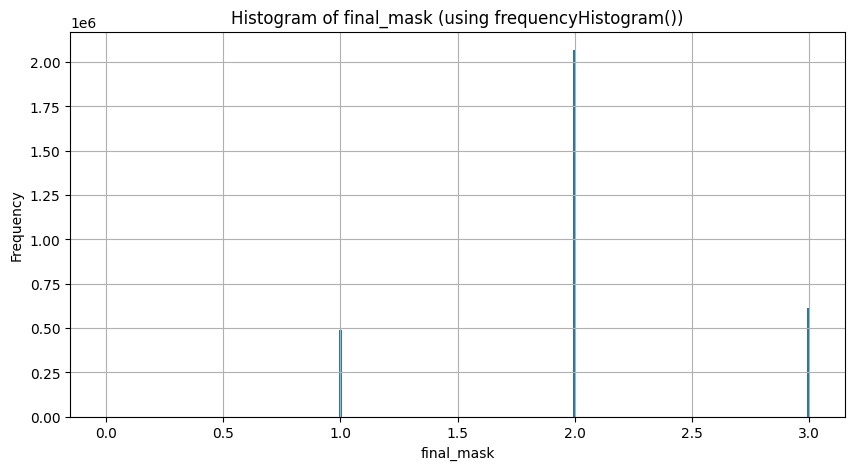

names of complete_set_of_masks ['dry_mask', 'bare_ground_mask', 'not_rangeland_mask', 'not_green_mask', 'final_mask', 'dry_and_bare_and_not_green_mask', 'dry_and_non_rangeland_and_not_green_mask']
print final_mask projection: {'type': 'Projection', 'crs': 'EPSG:32612', 'transform': [30, 0, 336885, 0, -30, 4732215]}
final mask band names: ['final_mask', 'NDWI_mean', 'EVI_mean', 'bare_ground', 'b1']
Projection of final_mask_dhs_sub: {'type': 'Projection', 'crs': 'EPSG:32612', 'transform': [30, 0, 336885, 0, -30, 4732215]}


Map(center=[41.40961929225168, -112.91016124780698], controls=(WidgetControl(options=['position', 'transparent…

In [ ]:
#@title Gather random dry, bare, not green points, Step 5: Create final mask for random points
# Step 5 sets up mask options and combines them into single mask for step 6.

# add ndwi, evi, fc, and lc mask
nwdi_evi = landsat_mean_data_dhs_sub_reproj.select('NDWI_mean','EVI_mean')

all_the_data = nwdi_evi.addBands(fc_dhs_sub_reproj).addBands(fc_v7_lc_mask_dhs_sub_reproj)

print('names of all the data:', all_the_data.bandNames().getInfo())


# Note: There is an argument to aggregate up to 100-500m
# to account for potential improved accuracy of fractional cover and,
# possibly, reflectance indices via modifiable areal unit problem considerations.
# See Rigge et al. 2025 here:
# https://www.sciencedirect.com/science/article/pii/S1550742425000053?ref=cra_js_challenge&fr=RR-1
# However, we do not follow this approach because much of our source areas
# do not have fractional cover data. This makes it highly likely
# that we encounter aggregations of a mix of rangeland and non-rangeland pixels,
# so the asymptotic properties of the means derived in this process are not
# certain, and could potentially even worsen things from a fractional cover
# perspective. The same may not be true for VI or NDWI indices. Nevertheless,
# for consistency, we keep things at 30m. This is arguably still a very
# strong approach compared to other alternatives. A quote from the paper
# above is: "Bare ground is the most accurate component based on independent
# validation (Rigge et al. 2024) and exhibits the lowest degree of scale
# dependency (3.39% relative increase in r and 25.9% relative reduction
# in RMSE, Table 2)". And the correlations reported in their figure 2 are
# approximately > 0.93, which is extremely high.


# (1) dry mask: convert to a 0 or 1 dry mask
dry_mask_final = all_the_data.select('NDWI_mean').lt(0).rename('dry_mask')

dry_mask_final = dry_mask_final.unmask(0)

print('names of dry mask:', dry_mask_final.bandNames().getInfo())


# (2) majority bare ground mask: convert to a 0 or 1 using bare_ground_mean >= 50
bare_ground_mask_final = all_the_data.select('bare_ground').gte(50).rename('bare_ground_mask')

bare_ground_mask_final = bare_ground_mask_final.unmask(0)

print('names of bare ground mask:', bare_ground_mask_final.bandNames().getInfo())


# (3) non-rangeland mask: convert to a 0 or 1 non-rangeland mask (this is already binary)
not_rangeland_mask_final = all_the_data.select('b1').rename('not_rangeland_mask')

not_rangeland_mask_final = not_rangeland_mask_final.unmask(0)

print('names of non-rangeland mask:', not_rangeland_mask_final.bandNames().getInfo())


# (4) not-green mask: convert to a 0 or 1 if EVI is less than 0.1
not_green_mask_final = all_the_data.select('EVI_mean').lt(0.1).rename('not_green_mask')

not_green_mask_final = not_green_mask_final.unmask(0)

print('names of not green mask:', not_green_mask_final.bandNames().getInfo())



# Combine the masks together into a single image with these bands and add them together
# to create the final mask
final_set_of_masks = dry_mask_final.addBands(bare_ground_mask_final).\
addBands(not_rangeland_mask_final).addBands(not_green_mask_final)

print('final combo of masks names', final_set_of_masks.bandNames().getInfo())



def create_final_mask(image):

  # select the bands
  dry_mask = image.select('dry_mask')
  bare_ground_mask = image.select('bare_ground_mask')
  not_rangeland_mask = image.select('not_rangeland_mask')
  not_green_mask = image.select('not_green_mask')

  # Calculate final mask:
  final_mask = image.expression('dry_mask + bare_ground_mask + not_rangeland_mask + not_green_mask',\
  { 'dry_mask': dry_mask, 'bare_ground_mask': bare_ground_mask, 'not_rangeland_mask': not_rangeland_mask,\
   'not_green_mask': not_green_mask}).rename('final_mask')

  # And calculate dry and bare and not green: (dry + majority bare ground + not-green)
  dry_and_bare_and_not_green_mask = image.expression('dry_mask + bare_ground_mask + not_green_mask',\
  { 'dry_mask': dry_mask, 'bare_ground_mask': bare_ground_mask,\
   'not_green_mask': not_green_mask}).rename('dry_and_bare_and_not_green_mask')

  # And calculate dry and non-rangeland and not green: (dry + non-rangeland + not-green)
  dry_and_non_rangeland_and_not_green_mask = image.expression('dry_mask + not_rangeland_mask + not_green_mask',\
  { 'dry_mask': dry_mask, 'not_rangeland_mask': not_rangeland_mask,\
   'not_green_mask': not_green_mask}).rename('dry_and_non_rangeland_and_not_green_mask')

  # Add the masks to the image
  return image.addBands([final_mask, dry_and_bare_and_not_green_mask, dry_and_non_rangeland_and_not_green_mask])

#final_set_of_masks_test = final_set_of_masks.map(crea#te_final_mask)

complete_set_of_masks = create_final_mask(final_set_of_masks)

# Check the bands
print('Bands after adding final_mask:', complete_set_of_masks.bandNames().getInfo())


# Test histogram and summary stats of each mask of interest
var_of_interest = complete_set_of_masks.select('final_mask')
var_of_interest_name = 'final_mask'

# Calculate summary statistics for the mask of interest
stats_of_interest = var_of_interest.reduceRegion(
    reducer=ee.Reducer.minMax().combine(ee.Reducer.mean().combine(ee.Reducer.stdDev(), sharedInputs=True), sharedInputs=True),
    geometry= dhs_sub_reproj,
    scale=30#, # Adjust scale as needed
    #maxPixels=1e9
)

# Print the statistics
print('summary stats', stats_of_interest.getInfo())


histogram_dict = var_of_interest.reduceRegion(
    reducer=ee.Reducer.frequencyHistogram(),
    geometry=dhs_sub_reproj,  # or any other geometry
    scale=30,  # adjust as needed
).getInfo()


# Selected variable of interest
hist_of_var_of_interest = histogram_dict.get(var_of_interest_name)

# Check if the histogram is valid
if hist_of_var_of_interest is None:
    print("No data available in the selected region")
else:
    # Prepare data for plotting
    values = list(map(float, hist_of_var_of_interest.keys()))
    counts = list(hist_of_var_of_interest.values())

    # Sort the data
    values, counts = zip(*sorted(zip(values, counts)))

    # Plot
    plt.figure(figsize=(10, 5))
    plt.bar(values, counts, width=0.01)  # Adjust width for better visuals
    plt.xlabel(var_of_interest_name)
    plt.ylabel('Frequency')
    var_of_interest_string = 'Histogram of ' + var_of_interest_name + ' (using frequencyHistogram())'
    plt.title(var_of_interest_string)
    plt.grid(True)
    plt.show()


# Separate additional masks to help assess how good "final mask" is doing and
# visually assess that final mask works as intended.
# Intuition: In step 4 above the following combinations were identified.
# (dry + majority bare ground + not-green) and (dry + non-rangeland + not-green)
# Each of these sets is comprised of three masks. So the summation will be 3
# when the respective masks are summed together. Why?
# Because:
# (a) (dry + majority bare ground + not-green) will only be captured in some
# subsets of the landscape within each source area / dhs_sub,
# particularly where v7 RCMAP fractional cover data is available.
# (b) (dry + non-rangeland + not-green) will only be captured in other
# subsets of the landscape within each source area / dhs_sub,
# particularly where there is no v7 RCMAP data.
# So in both cases, (a) and (b), the sum of the set of 4 masks will at maximum
# be 3 because these four masks do not overlap in space,
# i.e., although NDWI and EVI are everywhere (except with instances of clouds etc.),
# the bare ground data and non-rangeland subsets are mutually exclusive.
# Also separate water mask and green mask as well to plot those as desired.


# (5) water mask: convert to a 0 or 1 wet mask
water_mask_final = all_the_data.select('NDWI_mean').gte(0).rename('wet_mask').selfMask()
water_mask_final_dhs_sub = water_mask_final.clip(dhs_sub)

# (6) green mask: convert to a 0 or 1 green mask
green_mask_final = all_the_data.select('EVI_mean').gte(0.1).rename('wet_mask').selfMask()
green_mask_final_dhs_sub = green_mask_final.clip(dhs_sub)

# (7) show dry + bare + not green: convert to 0 or 1
dry_and_bare_and_not_green_mask = complete_set_of_masks.\
select('dry_and_bare_and_not_green_mask').eq(3).rename('dry_and_bare_and_not_green_mask').selfMask()

dry_and_bare_and_not_green_mask_dhs_sub = dry_and_bare_and_not_green_mask.clip(dhs_sub)

# (8) show dry + non-rangelands mask: convert to a 0 or 1 dry AND non-rangeland mask
dry_and_non_rangeland_and_not_green_mask = complete_set_of_masks.\
select('dry_and_non_rangeland_and_not_green_mask').eq(3).rename('dry_and_non_rangeland_and_not_green_mask').selfMask()

dry_and_non_rangeland_and_not_green_mask_dhs_sub = dry_and_non_rangeland_and_not_green_mask.clip(dhs_sub)


# (9) final step: set aside the final mask: mask everything that isn't a 3
print('names of complete_set_of_masks', complete_set_of_masks.bandNames().getInfo())
final_mask = complete_set_of_masks.select('final_mask').eq(3).selfMask()

#  Check projection of final_mask before adding all the data to it
# and then add it back to the final_mask (before clipping)
print('print final_mask projection:', final_mask.projection().getInfo())


# Combine with reprojected bands
final_mask_with_all_bands = final_mask.addBands(all_the_data)

# Clip and mask
final_mask_with_all_bands = final_mask_with_all_bands.updateMask(final_mask)

# Check output
print('final mask band names:', final_mask_with_all_bands.bandNames().getInfo())
print('Projection of final_mask_dhs_sub:', final_mask_with_all_bands.select('final_mask').projection().getInfo())



# for plotting the mask...
final_mask_dhs_sub_only = final_mask_with_all_bands.select('final_mask')


# Check if any pixels are present in the mask (silenced to stop timing out...)
#count_check = final_mask_dhs_sub.reduceRegion(
#    reducer=ee.Reducer.count(),
#    geometry=dhs_sub,
#    scale=30,
#    maxPixels=1e9
#)
#print('Pixel count in final mask:', count_check.getInfo())


# Create a map of the final mask with the two masks that comprise it:
#  (dry + bare + not-green) AND (dry + non-rangeland + not-green)

# Plot visual spectrum, final mask, the other to primary masks, and green and wet if desired

visual_spectrum_viz = {
  'bands': ['SR_B3_mean', 'SR_B2_mean', 'SR_B1_mean'],
  'min': 0.0,
  'max': 0.3,
}


final_mask_viz = {
    'min': 0,
    'max': 1,
    'palette': ['#FFA500']
}


green_viz = {
    'min': 0,
    'max': 1,
    'palette': ['#008000']
}

water_viz = {
    'min': 0,
    'max': 1,
    'palette': ['0000FF']
}

dry_and_bare_and_not_green_mask_viz = {
    'min': 0,
    'max': 1,
    'palette': ['ffffff', '#873600']
}

dry_and_non_rangeland_and_not_green_mask_viz = {
    'min': 0,
    'max': 1,
    'palette': ['ffffff', '#B0B0B0']
}


# Plot the layers of interest
m = geemap.Map()
m.centerObject(dhs_sub, 10)
l754_col_ind_viz = l754_col_ind.select(['SR_B3', 'SR_B2', 'SR_B1'])#.first()
l754_col_ind_viz_mn = ee.ImageCollection(l754_col_ind_viz).reduce(ee.Reducer.mean())
m.addLayer(l754_col_ind_viz_mn, visual_spectrum_viz, 'True Color (432)')

dhs_sub_line = dhs_sub_reproj.style(**{'fillColor': '00000000'})
styled_fc = dhs_sub.style(**{
    'color': '#000000',      # Outline color (e.g., red)
    'width': 30,             # Line width in pixels
    'fillColor': '00000000' # Transparent fill
})

m.addLayer(dhs_sub_line, {}, "dhs polygon")




# Add green and/or water masks for visualization as desired
m.addLayer(water_mask_final_dhs_sub, water_viz, 'water mask')

m.addLayer(green_mask_final_dhs_sub, green_viz, 'green mask')



m.addLayer(final_mask_dhs_sub_only, final_mask_viz, 'final mask for random points')


m.addLayer(dry_and_bare_and_not_green_mask_dhs_sub,\
           dry_and_bare_and_not_green_mask_viz, 'dry and bare and not-green')

m.addLayer(dry_and_non_rangeland_and_not_green_mask_dhs_sub,\
           dry_and_non_rangeland_and_not_green_mask_viz, 'dry and non-rangeland mask and not-green')

m


In [ ]:
#@title Gather random dry, bare, not green points, Step 6: Select random points from final mask, export data
# For Step 6, select random 5% and split it into 1% (to use) and 4% (in reserve)
# and export the 1% and 4% respectively, along with other supporting data.

# Assess properties of sources area
print('Type of dhs_sub_reproj:', type(dhs_sub_reproj))

num_features = dhs_sub_reproj.size().getInfo()
print('Number of features in dhs_sub_reproj:', num_features)

# Assess properties of final mask from step 5
print('final mask band names', final_mask_with_all_bands.bandNames().getInfo())


pix_count = final_mask_with_all_bands.select('final_mask').reduceRegion(
    reducer = ee.Reducer.sum(),
    geometry = dhs_sub_reproj.geometry(),  # there's only one feature in the collection so this works
    scale = 30,
    maxPixels = 1e9
)


print('Count of dry, bare, and non-green pixels:', pix_count.getInfo())


# convert to a number and print numbers of pixels and
# select desired percentage of dry pixels to get number of dry, bare, and not-green pixels to randomly sample
# https://gis.stackexchange.com/questions/255266/how-can-i-summarize-all-the-pixels-from-a-single-raster-using-google-earth-engin
pix_count_dict = pix_count.getInfo()

num_dry_bare_and_non_green_pixels = round(pix_count_dict['final_mask'])
print('Total dry, bare, and not-green pixels:', num_dry_bare_and_non_green_pixels)

num_to_sample_5_prcnt = round(num_dry_bare_and_non_green_pixels * 0.05)
print('Number of point to sample to get 5% of the total points:', num_to_sample_5_prcnt)



# convert final mask into a vector to export (saves much space compared to raster)
final_mask_dhs_sub_only = final_mask_with_all_bands.select('final_mask')


final_mask_dhs_sub_poly = final_mask_dhs_sub_only.reduceToVectors(
  geometry = dhs_sub_reproj.geometry(),
  crs = final_mask_dhs_sub_only.projection(),
  scale = 30,
  geometryType = 'polygon',
  eightConnected = False,
  labelProperty = 'final_mask'
)

# export this polygon to earth engine assets for eacy year-source-area combo
final_mask_dhs_sub_poly_info = year + '_' + dhs_sub_name + '_final_dry_bare_not_green_poly'

final_mask_dhs_sub_shp = ee.FeatureCollection(final_mask_dhs_sub_poly)

task_poly = ee.batch.Export.table.toAsset(
    collection = final_mask_dhs_sub_shp,
    description = final_mask_dhs_sub_poly_info + '_export',  # Task name
    assetId='projects/gsl-dust/assets/'+final_mask_dhs_sub_poly_info # Full asset path
)
task_poly.start()



# Simplify and clean each feature's geometry
simplified_fc = final_mask_dhs_sub_poly.map(
    lambda f: f.setGeometry(f.geometry().simplify(30))  # Match Landsat scale
)

# Fix geometry topology by buffering with a non-zero error margin
cleaned_fc = simplified_fc.map(
    lambda f: f.setGeometry(f.geometry().buffer(0, 1))  # 1 meter maxError
)

# Merge into a single multi-polygon (not a collection)
sampling_region = cleaned_fc.union().geometry()



image_proj = final_mask_with_all_bands.select(0).projection()


try:
    random_points = ee.FeatureCollection.randomPoints(
        region=sampling_region,
        points=num_to_sample_5_prcnt,
        seed=8312,
         maxError=1
    )
    print('Successfully generated points.')
except Exception as e:
    print('Error generating random points:', e)


# silenced to avoid timing out...
#print('Number of random points generated:', random_points.size().getInfo())




# Inspect values at the first point
test_point = random_points.first()
test_sample = final_mask_with_all_bands.reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=test_point.geometry(),
    scale=30
)

#print('Band values at test point:', test_sample.getInfo())

# gather the mask value
def attach_mask_value(point):
    value = final_mask_with_all_bands.select('final_mask').reduceRegion(
        reducer=ee.Reducer.first(),
        geometry=point.geometry(),
        scale=30
    ).get('final_mask')
    return point.set('final_mask', value)

# Map over the points to attach the 'final_mask' value
random_points_with_mask = random_points.map(attach_mask_value)

# Filter to only the points where final_mask == 1
valid_points = random_points_with_mask.filter(ee.Filter.eq('final_mask', 1))

# Check how many valid points remain (silenced to avoid time out)
#print('Number of valid points on mask == 1:', valid_points.size().getInfo())

#print('First valid point (geometry):', valid_points.first().geometry().getInfo())


# test a value
test_point = ee.Feature(valid_points.first())

test_sample = final_mask_with_all_bands.reduceRegion(
    reducer=ee.Reducer.first(),
    geometry=test_point.geometry(),
    scale=30
)

#print('Band values at one valid point:', test_sample.getInfo())


filled_image = final_mask_with_all_bands.unmask(-9999)

# Sample values at valid points
samples_with_all_bands = filled_image.sampleRegions(
    collection=valid_points,
    scale=30,
    geometries=True
)

# Check output (silenced to avoid time out)
#print('Number of samples with bands:', samples_with_all_bands.size().getInfo())
#print('First sample properties:', samples_with_all_bands.first().toDictionary().getInfo())





# Add a random column to the 5% sample to parse this sample into
# a random 1% to use and random 4% to set aside for potential later use
#samples_random = samples.randomColumn(columnName='random', seed = 8312)
samples_random = samples_with_all_bands.randomColumn(columnName='random', seed=8312)

random_1pct = samples_random.filter(ee.Filter.lt('random', 0.2))   # 20% of 5% = 1%
random_4pct = samples_random.filter(ee.Filter.gte('random', 0.2))  # 80% of 5% = 4%

# silenced to avoid time out
#print('Number of points in 1% sample (20% of 5%):', random_1pct.size().getInfo())
#print('Number of points in 4% sample (80% of 5%):', random_4pct.size().getInfo())

# Add a sequential id to part out logical point ids
def add_sequential_id(fc):
    count = fc.size()
    seq = ee.List.sequence(1, count)
    zipped = fc.toList(count).zip(seq)
    with_seq = zipped.map(lambda f_s: ee.Feature(ee.List(f_s).get(0)).set('seq_num', ee.List(f_s).get(1)))
    return ee.FeatureCollection(with_seq)

random_1pct = add_sequential_id(random_1pct)
random_4pct = add_sequential_id(random_4pct)

# gather additional data for the export: id, long, lat, source area, year
def add_additional_columns(feature):
    seq_num = ee.Number(feature.get('seq_num'))
    seq_str = seq_num.format('%03d')
    year_str = ee.String(year)
    new_id = year_str.cat(seq_str)
    coords = feature.geometry().coordinates()
    lon = coords.get(0)
    lat = coords.get(1)
    return feature.set({
        'pnt_id': new_id,
        'longitude': lon,
        'latitude': lat,
        'region': dhs_sub_name,
        'year': year_str
    })

random_1pct_final = random_1pct.map(add_additional_columns)
random_4pct_final = random_4pct.map(add_additional_columns)



# Export results to GCS
final_mask_dhs_sub_random_1prcnt_info = year + '_' + dhs_sub_name + '_random_1prcnt_pnts'
final_mask_dhs_sub_random_4prcnt_info = year + '_' + dhs_sub_name + '_random_4prcnt_pnts'

# the 1% to GCS
task1 = ee.batch.Export.table.toCloudStorage(
    collection = random_1pct_final,
    description = 'export_to_GCS_'+'_final_mask_dhs_sub_random_1prcnt_info',
    bucket = 'dry_bare_not_green_points',
    fileNamePrefix = final_mask_dhs_sub_random_1prcnt_info,
    fileFormat = 'CSV'#,
    #selectors = ['year', 'region', 'latitude', 'longitude', 'seq_num', 'pnt_id', 'final_mask', 'system:index']
)
task1.start()

# the 1% to EE assets
task2 = ee.batch.Export.table.toAsset(
    collection = random_1pct_final,
    description = 'export_to_assets_'+'_final_mask_dhs_sub_random_1prcnt_info',
    assetId = 'projects/gsl-dust/assets/'+final_mask_dhs_sub_random_1prcnt_info#,
    #selectors = ['year', 'region', 'seq_num', 'pnt_id', 'final_mask', 'system:index', '.geo']
)
task2.start()

# the 4% to GCS
task3 = ee.batch.Export.table.toCloudStorage(
    collection = random_4pct_final,
    description = 'export_to_GCS_'+'_final_mask_dhs_sub_random_4prcnt_info',
    bucket = 'dry_bare_not_green_points',
    fileNamePrefix = final_mask_dhs_sub_random_4prcnt_info,
    fileFormat = 'CSV'#,
    #selectors = ['year', 'region', 'latitude', 'longitude', 'seq_num', 'pnt_id', 'final_mask', 'system:index']
)
task3.start()

# the 4% to EE assets
task4 = ee.batch.Export.table.toAsset(
    collection = random_4pct_final,
    description = 'export_to_assets_'+'final_mask_dhs_sub_random_4prcnt_info',
    assetId = 'projects/gsl-dust/assets/'+final_mask_dhs_sub_random_4prcnt_info#,
    #selectors = ['year', 'region', 'seq_num', 'pnt_id', 'final_mask', 'system:index', '.geo']
)
task4.start()


# plot to make sure it worked


visual_spectrum_viz = {
  'bands': ['SR_B3_mean', 'SR_B2_mean', 'SR_B1_mean'],
  'min': 0.0,
  'max': 0.3,
}


final_mask_viz = {
    'min': 0,
    'max': 1,
    'palette': ['#FFA500']
}


selected_1prcnt_viz = {
    'color': '#40E0D0',
    'pointSize': 1,
    'fillColor': '#40E0D0'
}

selected_4prcnt_viz = {
    'color': '#FFC0CB',
    'pointSize': 1,
    'fillColor': '#FFC0CB'
}


m = geemap.Map()
m.centerObject(dhs_sub, 10)
l754_col_ind_viz = l754_col_ind.select(['SR_B3', 'SR_B2', 'SR_B1'])#.first()
l754_col_ind_viz_mn = ee.ImageCollection(l754_col_ind_viz).reduce(ee.Reducer.mean())
m.addLayer(l754_col_ind_viz_mn, visual_spectrum_viz, 'True Color (432)')

dhs_sub_line = dhs_sub.style(**{'fillColor': '00000000'})

m.addLayer(dhs_sub_line, {}, "dhs polygon")


final_mask_dhs_sub_final = final_mask_with_all_bands.select('final_mask')
m.addLayer(final_mask_dhs_sub_final, final_mask_viz, 'final mask for random points')

#final_mask_dhs_sub_poly_line = final_mask_dhs_sub_poly.style(**{'fillColor': '00000000'})
#final_mask_dhs_sub_poly_line = final_mask_dhs_sub_poly.style(**{
#    'color': '#B0B0B0',      # Outline color (e.g., red)
#    'width': 30,             # Line width in pixels
#    'fillColor': '#000000' # Transparent fill
#})

m.addLayer(final_mask_dhs_sub_poly, {}, 'polygon around final mask')
#m.addLayer(random_1pct_final, selected_1prcnt_viz, 'final 1% selected points')
#m.addLayer(random_4pct_final, selected_4prcnt_viz, 'final 4% selected points')
m



Type of dhs_sub_reproj: <class 'ee.featurecollection.FeatureCollection'>
Number of features in dhs_sub_reproj: 1
final mask band names ['final_mask', 'NDWI_mean', 'EVI_mean', 'bare_ground', 'b1']
Count of dry, bare, and non-green pixels: {'final_mask': 610177.4627450984}
Total dry, bare, and not-green pixels: 610177
Number of point to sample to get 5% of the total points: 30509
Successfully generated points.


Map(center=[41.40961929225168, -112.91016124780698], controls=(WidgetControl(options=['position', 'transparent…

In [ ]:
#@title Extra code for plotting if step 6 times out...


# plot to make sure it worked


visual_spectrum_viz = {
  'bands': ['SR_B3_mean', 'SR_B2_mean', 'SR_B1_mean'],
  'min': 0.0,
  'max': 0.3,
}


final_mask_viz = {
    'min': 0,
    'max': 1,
    'palette': ['#FFA500']
}


selected_1prcnt_viz = {
    'color': '#40E0D0',
    'pointSize': 1,
    'fillColor': '#40E0D0'
}

selected_4prcnt_viz = {
    'color': '#FFC0CB',
    'pointSize': 1,
    'fillColor': '#FFC0CB'
}


m = geemap.Map()
m.centerObject(dhs_sub, 10)
l754_col_ind_viz = l754_col_ind.select(['SR_B3', 'SR_B2', 'SR_B1'])#.first()
l754_col_ind_viz_mn = ee.ImageCollection(l754_col_ind_viz).reduce(ee.Reducer.mean())
m.addLayer(l754_col_ind_viz_mn, visual_spectrum_viz, 'True Color (432)')

dhs_sub_line = dhs_sub.style(**{'fillColor': '00000000'})

m.addLayer(dhs_sub_line, {}, "dhs polygon")


final_mask_dhs_sub_final = final_mask_with_all_bands.select('final_mask')
m.addLayer(final_mask_dhs_sub_final, final_mask_viz, 'final mask for random points')

#final_mask_dhs_sub_poly_line = final_mask_dhs_sub_poly.style(**{'fillColor': '00000000'})
#final_mask_dhs_sub_poly_line = final_mask_dhs_sub_poly.style(**{
#    'color': '#B0B0B0',      # Outline color (e.g., red)
#    'width': 30,             # Line width in pixels
#    'fillColor': '#000000' # Transparent fill
#})

m.addLayer(final_mask_dhs_sub_poly, {}, 'polygon around final mask')

pnts_1prcnt_import_name = 'projects/gsl-dust/assets/'+year+'_'+dhs_sub_name+'_random_1prcnt_pnts'
random_1pct_final_imported = ee.FeatureCollection(pnts_1prcnt_import_name)

pnts_4prcnt_import_name = 'projects/gsl-dust/assets/'+year+'_'+dhs_sub_name+'_random_4prcnt_pnts'
random_4pct_final_imported = ee.FeatureCollection(pnts_4prcnt_import_name)


m.addLayer(random_1pct_final_imported, selected_1prcnt_viz, 'final 1% selected points')
m.addLayer(random_4pct_final_imported, selected_4prcnt_viz, 'final 4% selected points')

# Add green and/or water masks for visualization as desired
m.addLayer(water_mask_final_dhs_sub, water_viz, 'water mask')

m.addLayer(green_mask_final_dhs_sub, green_viz, 'green mask')


m



Map(center=[41.40961929225168, -112.91016124780698], controls=(WidgetControl(options=['position', 'transparent…